About Dataset

Context

"Predict behavior to retain customers. You can analyze all relevant customer data and develop focused customer retention programs." [IBM Sample Data Sets]


Content

Each row represents a customer, each column contains customer’s attributes described on the column Metadata.


The data set includes information about:


Customers who left within the last month – the column is called Churn
Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
Demographic info about customers – gender, age range, and if they have partners and dependents
Inspiration

To explore this type of models and learn more about the subject.


New version from IBM:
 https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113

# Telco Customer Churn Dataset Dictionary

## 1. Customer Identifiers & Target Variable

*   **`customerID`** `(String)`
    *   **Description:** A unique alphanumeric code assigned to each individual customer (e.g., `7590-VHVEG`).
    *   **Usage:** Used for record identification only. Exclude this from feature sets before machine learning modeling.
*   **`Churn`** `(Categorical / Target)`
    *   **Description:** Indicates whether the customer canceled their subscription within the last month (`Yes` or `No`).
    *   **Usage:** Primary target variable ($y$) for binary classification models.

---

## 2. Demographics

*   **`gender`** `(Categorical)`
    *   **Description:** Customer's self-reported gender (`Female` or `Male`).
*   **`SeniorCitizen`** `(Binary Integer)`
    *   **Description:** Indicates whether the customer is aged 65 or older (`1` = Yes, `0` = No).
*   **`Partner`** `(Categorical)`
    *   **Description:** Indicates whether the customer has a spouse or domestic partner (`Yes` or `No`).
*   **`Dependents`** `(Categorical)`
    *   **Description:** Indicates whether the customer has financial dependents such as children or elderly family members (`Yes` or `No`).

---

## 3. Account & Financial Information

*   **`tenure`** `(Integer)`
    *   **Description:** Total number of consecutive months the customer has maintained an active account ($0$ to $72$).
*   **`Contract`** `(Categorical)`
    *   **Description:** The billing agreement terms (`Month-to-month`, `One year`, `Two year`).
*   **`PaperlessBilling`** `(Categorical)`
    *   **Description:** Indicates whether invoices are delivered electronically instead of via physical mail (`Yes` or `No`).
*   **`PaymentMethod`** `(Categorical)`
    *   **Description:** Customer's selected payment channel (`Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)`).
*   **`MonthlyCharges`** `(Float)`
    *   **Description:** The total dollar amount billed to the customer for their monthly plan and active services.
*   **`TotalCharges`** `(Float / String)`
    *   **Description:** Cumulative dollar amount billed to the customer over their entire lifetime with the company.
    *   **Note:** Contains blank string spaces (`" "`) for new accounts (`tenure = 0`) that require numeric coercion (`pd.to_numeric`).

---

## 4. Primary Telecommunication Services

*   **`PhoneService`** `(Categorical)`
    *   **Description:** Indicates subscription to home landline telephone services (`Yes` or `No`).
*   **`MultipleLines`** `(Categorical)`
    *   **Description:** Indicates access to multiple telephone lines (`Yes`, `No`, or `No phone service`).
*   **`InternetService`** `(Categorical)`
    *   **Description:** Customer's primary network connection technology (`DSL`, `Fiber optic`, or `No`).

---

## 5. Add-On Services

> *Note: If `InternetService` is `No`, all six add-on features default to `No internet service`.*

*   **`OnlineSecurity`** `(Categorical)`
    *   **Description:** Subscription to web safety and antivirus protection features (`Yes`, `No`, `No internet service`).
*   **`OnlineBackup`** `(Categorical)`
    *   **Description:** Subscription to cloud-based file backup services (`Yes`, `No`, `No internet service`).
*   **`DeviceProtection`** `(Categorical)`
    *   **Description:** Subscription to hardware replacement/repair insurance (`Yes`, `No`, `No internet service`).
*   **`TechSupport`** `(Categorical)`
    *   **Description:** Subscription to priority customer technical assistance (`Yes`, `No`, `No internet service`).
*   **`StreamingTV`** `(Categorical)`
    *   **Description:** Subscription to live IP television streaming (`Yes`, `No`, `No internet service`).
*   **`StreamingMovies`** `(Categorical)`
    *   **Description:** Subscription to on-demand movie streaming (`Yes`, `No`, `No internet service`).

In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Path to dataset files: /home/mg/.cache/kagglehub/datasets/blastchar/telco-customer-churn/versions/1


# import library

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [ ]:
#finde fiels in path
os.listdir(path=path)

['WA_Fn-UseC_-Telco-Customer-Churn.csv']

In [10]:
# reading the data
df=pd.read_csv(path+"/"+'WA_Fn-UseC_-Telco-Customer-Churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [11]:
# info 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [12]:
# finda sum null value
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
# convert TotalCharges to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [14]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [ ]:
# Replace missing values using (tenure * MonthlyCharges)
# For tenure = 0, this evaluates to 0
df['TotalCharges'] = df['TotalCharges'].fillna(df['tenure'] * df['MonthlyCharges'])

In [18]:
# Drop customer_id from data and duplicates

df.drop_duplicates(inplace=True)
df.drop(["customerID"] ,axis=1,inplace=True)

In [20]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## Target Variable Distribution (Churn Rate)

/tmp/ipykernel_35083/2443308032.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Churn', palette=['#2b5c8f', '#d95f02'])


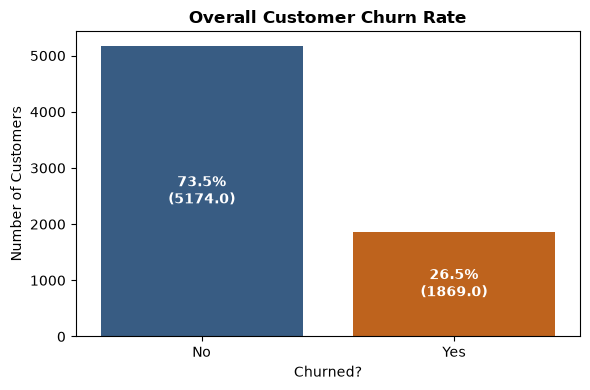

In [21]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='Churn', palette=['#2b5c8f', '#d95f02'])
plt.title('Overall Customer Churn Rate', fontsize=12, fontweight='bold')
plt.xlabel('Churned?')
plt.ylabel('Number of Customers')

# Add percentage labels to bars
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%\n({p.get_height()})'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

## Numerical Variables Analysis

/tmp/ipykernel_35083/652748080.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[0], palette=['#2b5c8f', '#d95f02'])
/tmp/ipykernel_35083/652748080.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='TotalCharges', ax=axes[2], palette=['#2b5c8f', '#d95f02'])


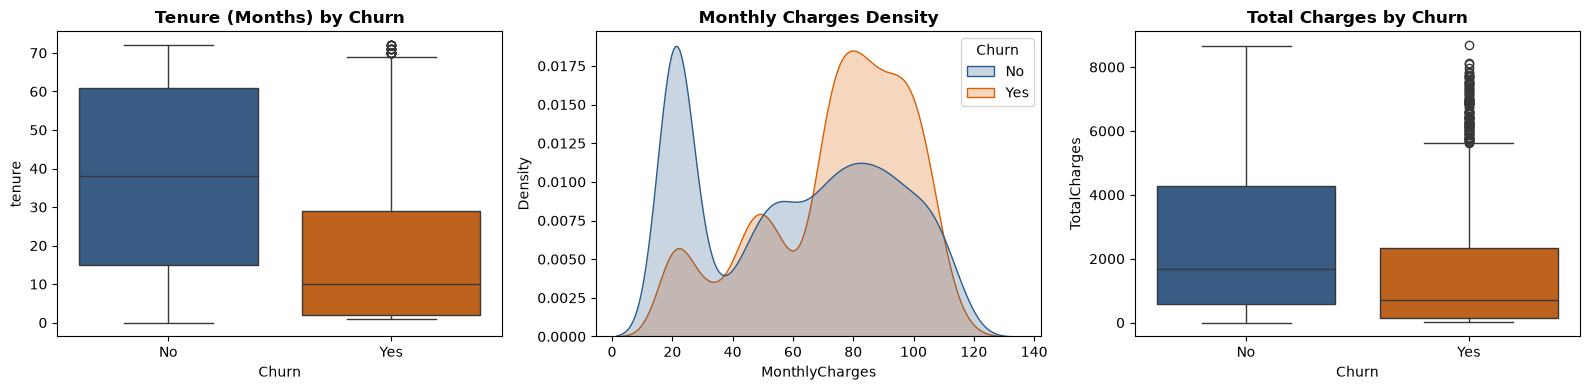

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Tenure vs Churn
sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_title('Tenure (Months) by Churn', fontweight='bold')

# 2. Monthly Charges Distribution
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', common_norm=False, 
            fill=True, ax=axes[1], palette=['#2b5c8f', '#d95f02'])
axes[1].set_title('Monthly Charges Density', fontweight='bold')

# 3. Total Charges vs Churn
sns.boxplot(data=df, x='Churn', y='TotalCharges', ax=axes[2], palette=['#2b5c8f', '#d95f02'])
axes[2].set_title('Total Charges by Churn', fontweight='bold')

plt.tight_layout()
plt.show()

## Primary Risk Factors (Contract, Internet & Payment)

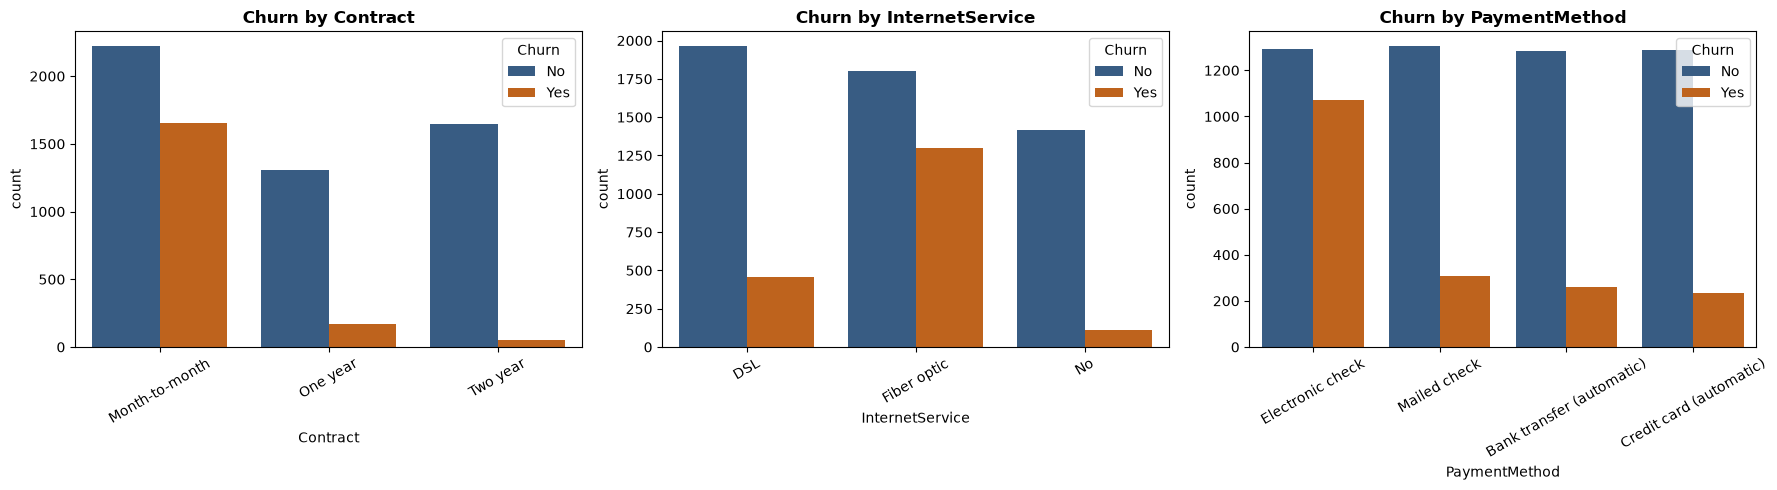

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cat_cols = ['Contract', 'InternetService', 'PaymentMethod']
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue='Churn', ax=axes[i], palette=['#2b5c8f', '#d95f02'])
    axes[i].set_title(f'Churn by {col}', fontweight='bold')
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## Impact of Add-on Services on Retention

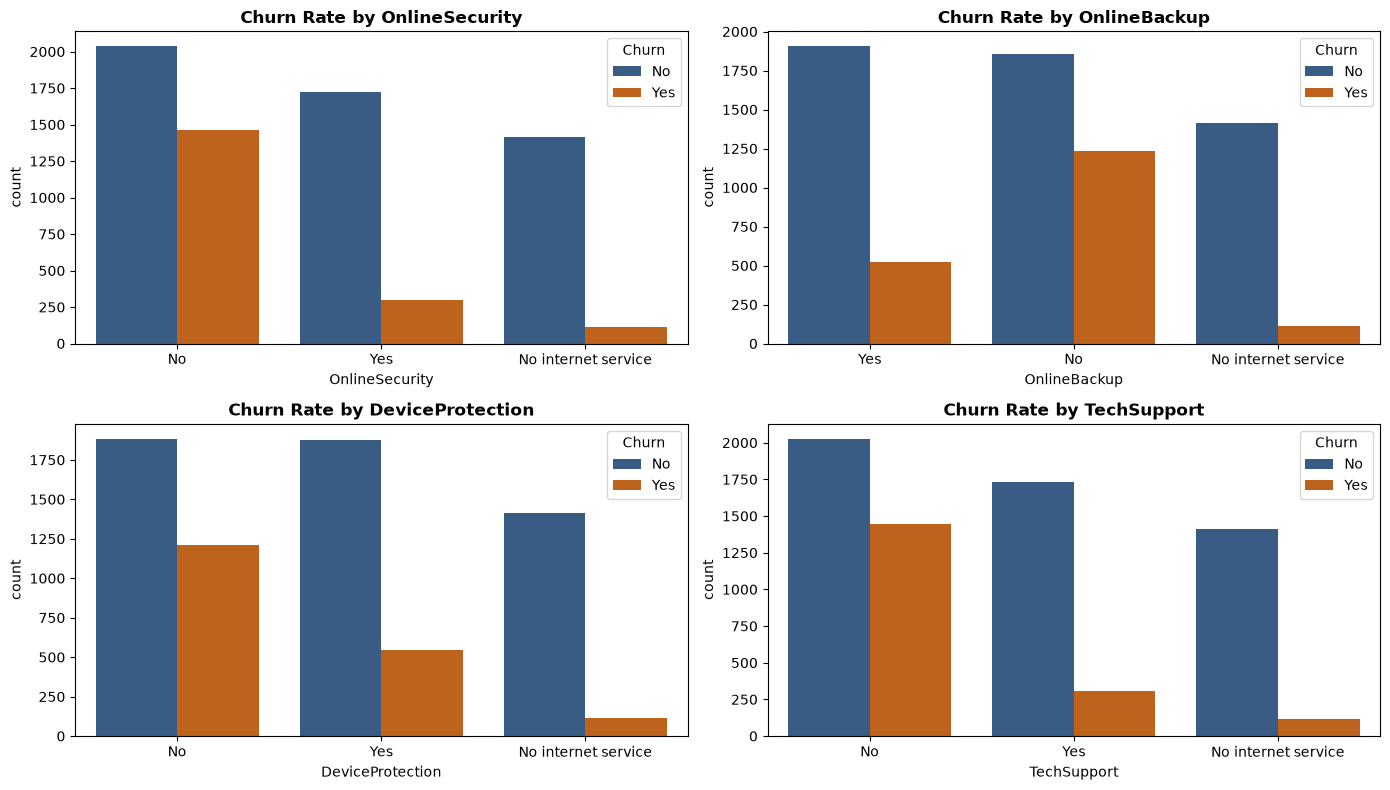

In [24]:
add_ons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for i, col in enumerate(add_ons):
    ax = axes[i // 2, i % 2]
    sns.countplot(data=df, x=col, hue='Churn', ax=ax, palette=['#2b5c8f', '#d95f02'])
    ax.set_title(f'Churn Rate by {col}', fontweight='bold')

plt.tight_layout()
plt.show()

## Correlation Heatmap

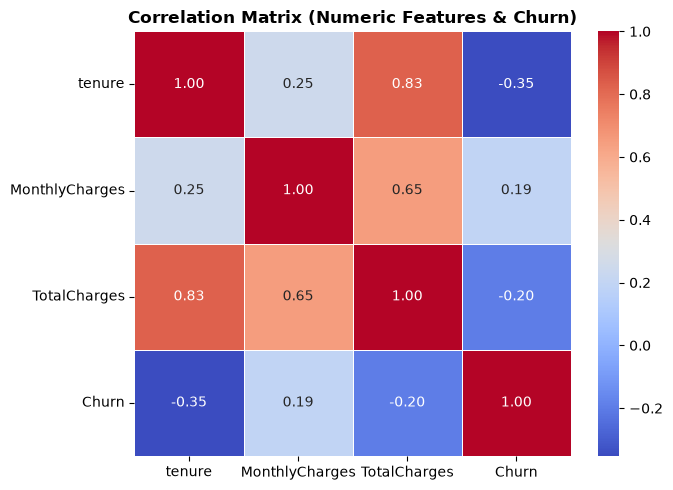

In [25]:
plt.figure(figsize=(7, 5))

# Prepare numeric dataset including mapped target
num_df = df[['tenure', 'MonthlyCharges', 'TotalCharges']].copy()
num_df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix (Numeric Features & Churn)', fontweight='bold')
plt.tight_layout()
plt.show()

In [26]:
os.getcwd()

'/home/mg/my_venv/notebooks'

In [28]:
df.to_csv('/home/mg/my_venv/notebooks/WA_Fn-UseC_-Telco-Customer-Churn.csv')